# Predicting Corporate Financial Distress from Financial-Statement Ratios

**Question:** Using only information a firm has already reported in fiscal year *t*, is it possible to flag which firms will be in financial distress in year *t+1*?

**Approach:** Ratio features built from LSEG (Refinitiv) fundamentals → logistic regression (baseline, L1, L2) tuned with grid search

| Section | What it covers |
|---|---|
| 1 | The data: what it looks like and the cleaning / organizing challenges |
| 2 | Suitable algorithms and the hyperparameters to tune |
| 3 | Success criteria, with results |
| 4 | Where I need help / open questions |

In [1]:
import warnings, os
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, roc_curve, precision_recall_curve)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# ---- modeling table built from LSEG data (one row per firm-fiscal-year) ----
m = pd.read_csv("distress_model_data.csv", parse_dates=["PeriodEnd"])

feat = ["wc_ta", "re_ta", "ebit_ta", "mve_tl", "sales_ta", "tl_ta", "debt_ta", "cur_ratio",
        "cash_ta", "roa", "cfo_ta", "cov", "log_ta", "log_mc"]
print(f"{len(m):,} firm-years | {m['ric'].nunique():,} firms | fiscal years {int(m['fy'].min())}-{int(m['fy'].max())}")

17,164 firm-years | 1,908 firms | fiscal years 2007-2023


---
# 1. The data

### Source and universe
- **Source:** LSEG Data Library (Refinitiv) annual fundamentals, pulled through the API: 19 line items per firm-year (balance sheet, income statement, cash flow, market cap) plus fiscal period-end and original announcement dates.
- **Universe:** every member of the **S&P 500, S&P 400 and S&P 600** (about 1,500 firms in any given year), 2007–2023.
- **Avoiding survivorship bias:** today's index list would contain only survivors, so I rebuilt membership *point-in-time* from the index joiner/leaver history, starting from today's list and undoing every change backward. The reconstruction stays within about 1–2% of the true index size every year. This brings in **1,328 retired tickers** (acquired, bankrupt, delisted), which the API exposes with a `^` suffix (e.g. `SHLD.OQ^J18`).
- **Excluded:** financials (banks and insurers have no meaningful current assets or working capital), and firm-years before a firm joined or after it left the index.

In [2]:
funnel = pd.DataFrame({
    "Step": ["Raw firm-years pulled from API (2,894 tickers)",
             "Valid period-end and total assets, de-duplicated, financials removed",
             "Firm was an index member in that fiscal year",
             "Has a t+1 label and complete features (FY2007-2023)"],
    "Rows": [42960, 35820, 22552, len(m)],
})
funnel["Dropped"] = (-funnel["Rows"].diff()).fillna(0).astype(int)
funnel

,Step,Rows,Dropped
0,"Raw firm-years pulled from API (2,894 tickers)",42960,0
1,"Valid period-end and total assets, de-duplicat...",35820,7140
2,Firm was an index member in that fiscal year,22552,13268
3,Has a t+1 label and complete features (FY2007-...,17164,5388


### What the modeling table looks like
Each row is one firm in one fiscal year. Columns are ratio features measured at year *t*, plus a label for year *t+1*.

In [3]:
show = ["ric", "PeriodEnd", "trbc_sector", "wc_ta", "re_ta", "ebit_ta", "mve_tl", "tl_ta", "cov", "distress_t", "label"]
show = [c for c in show if c in m.columns]
m[show].sample(8, random_state=1).round(3)

,ric,PeriodEnd,trbc_sector,wc_ta,re_ta,ebit_ta,mve_tl,tl_ta,cov,distress_t,label
466,AGCO.N,2021-12-31,Industrials,0.170,0.564,0.111,1.367,0.625,40.028,0.0,0.0
13398,SANM.OQ,2017-09-30,Technology,0.260,-1.035,0.059,1.273,0.572,10.325,0.0,0.0
7529,HZO.N,2018-09-30,Consumer Cyclicals,0.280,0.259,0.099,1.995,0.449,6.380,0.0,0.0
3831,CSL.N,2012-12-31,Consumer Cyclicals,0.213,0.517,0.109,2.222,0.483,14.542,0.0,0.0
13785,SKYD.N,2018-12-31,Consumer Cyclicals,0.080,0.125,0.125,0.482,0.764,5.389,0.0,0.0
8097,JAKK.OQ,2012-12-31,Consumer Cyclicals,0.336,0.016,-0.024,0.793,0.627,-1.433,0.0,1.0
5044,ED.N,2013-12-31,Utilities,-0.021,0.205,0.058,0.570,0.699,4.061,0.0,0.0
5868,FELE.OQ,2020-12-31,Industrials,0.327,0.601,0.105,7.571,0.332,28.748,0.0,0.0


### Features (all measured at fiscal year *t*)
| Feature | Definition | Idea |
|---|---|---|
| `wc_ta` | (current assets − current liabilities) / assets | liquidity |
| `re_ta` | retained earnings / assets | cumulative profitability |
| `ebit_ta` | EBIT / assets | operating profitability |
| `mve_tl` | market cap / total liabilities | market-implied cushion |
| `sales_ta` | revenue / assets | asset turnover |
| `tl_ta`, `debt_ta` | total liabilities, total debt over assets | leverage |
| `cur_ratio`, `cash_ta` | current ratio; cash / assets | short-term liquidity |
| `roa`, `cfo_ta` | net income / assets; operating cash flow / assets | profitability, cash generation |
| `cov` | EBIT / interest expense (clipped at ±50) | debt-service capacity |
| `log_ta`, `log_mc` | log assets; log market cap | size |

The first five are the Altman Z-score ingredients, which gives us a classic benchmark to compare against.

### The label: distress in the *next* year
A firm-year is labeled **1** if in year *t+1* **EBIT < interest expense** (it does not cover its interest) **and** either operating cash flow is negative or total liabilities exceed total assets.
- **Features at year t, label at t+1** avoids leakage: the label is built from some of the same variables as the features, so using same-year values would make the problem circular.
- **Firms that disappear** have no next-year financials. For a retired ticker's last observed year, the delisting date is encoded in the ticker (`^G15` means July 2015). If it delisted within 18 months and its final year looked distressed (distress flag or liabilities > assets), it is labeled 1; if it was healthy (e.g. acquired), 0.

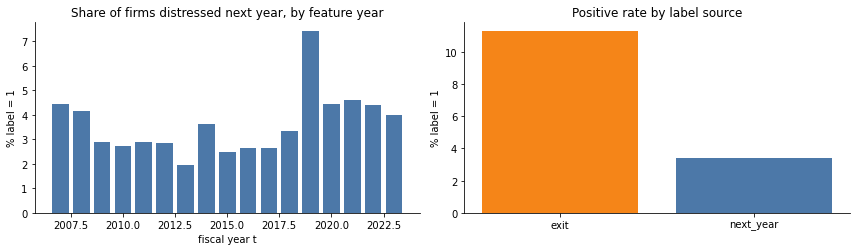

Positives: 625 of 17,164 (3.64%)  -> heavily imbalanced
P(distress next year | distressed now) = 56.7%  |  P(distress next year | healthy now) = 2.0%


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
by_year = m.groupby("fy")["label"].agg(["size", "sum", "mean"])
ax[0].bar(by_year.index, by_year["mean"] * 100, color="#4C78A8")
ax[0].set_title("Share of firms distressed next year, by feature year")
ax[0].set_ylabel("% label = 1"); ax[0].set_xlabel("fiscal year t")
if "label_src" in m.columns:
    s = m.groupby("label_src")["label"].agg(["size", "sum", "mean"])
    ax[1].bar(s.index, s["mean"] * 100, color=["#F58518", "#4C78A8"][:len(s)])
    ax[1].set_title("Positive rate by label source"); ax[1].set_ylabel("% label = 1")
plt.tight_layout(); plt.show()

print(f"Positives: {int(m['label'].sum()):,} of {len(m):,} ({m['label'].mean():.2%})  -> heavily imbalanced")
if "distress_t" in m.columns:
    print("P(distress next year | distressed now) = %.1f%%  |  P(distress next year | healthy now) = %.1f%%"
          % (100 * m.loc[m.distress_t == 1, 'label'].mean(), 100 * m.loc[m.distress_t == 0, 'label'].mean()))

**Reading the plots:** distress is rare (~3-4% of firm-years) and clusters around known stress periods (2007-09; the 2019 feature year, i.e. COVID in 2020). Roughly half of distressed firms are still distressed a year later, so a naive "same as last year" rule is a strong baseline. The more useful question is catching firms *before* they become distressed, which can also be reported.

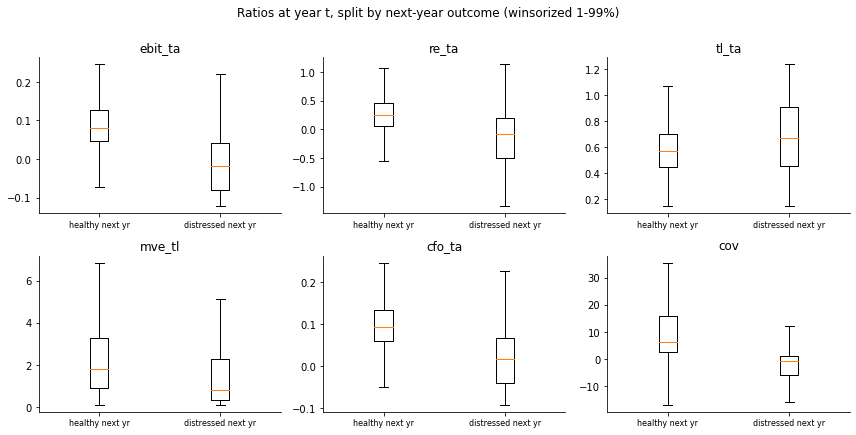

In [5]:
plot_feats = ["ebit_ta", "re_ta", "tl_ta", "mve_tl", "cfo_ta", "cov"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for a, f in zip(axes.ravel(), plot_feats):
    lo, hi = m[f].quantile([0.01, 0.99])
    data = [m.loc[m.label == k, f].clip(lo, hi).dropna() for k in (0, 1)]
    a.boxplot(data, showfliers=False)
    a.set_xticklabels(["healthy next yr", "distressed next yr"], fontsize=8)
    a.set_title(f)
plt.suptitle("Ratios at year t, split by next-year outcome (winsorized 1-99%)", y=1.0)
plt.tight_layout(); plt.show()

### Cleaning and organizing challenges
1. **Survivorship bias.** `0#.SPX(date)` simlpy returns *today's* constituents; the index list at a past date had to be reconstructed from joiner/leaver events. Ordering mattered as undoing changes oldest-first inflated index sizes to ~660 vs 500 until I processed them newest-first.
2. **Retired tickers.** Delisted firms only resolve under caret-suffixed RICs (e.g. `LEH.N^I08`); using the plain ticker fails. 34 retired tickers (about 1%) have no financial data at all (e.g. Lehman Brothers).
3. **Field discovery.** A few of the line items like receivables and inventory had only 3% and 63% coverage respectively (structurally missing for service firms), so both were dropped.
4. **Unavailability of data is not a distress signal.** Coverage for retired vs active firms differs by only 2-4 points (e.g. revenue 96.5% vs 99.3%).
5. **Timing.** Fiscal years end in different months and results are announced weeks later, so each row keeps both the period-end and the original announcement date for point-in-time alignment.
6. **Sector is today's classification**, not historical.

---
# 2. Suitable algorithms and hyperparameters

**Why logistic regression first:** the target is binary and imbalanced, the features are interpretable financial ratios, and a transparent model (coefficients = ratio effects) is easy to defend. It is also the classic form of distress models (Ohlson 1980).

| Model | Hyperparameter(s) to tune | Notes |
|---|---|---|
| Logistic regression, near-unregularized (baseline) | none (C = 10⁶) | reference point |
| Logistic regression + **L1** (lasso) | `C` (inverse regularization strength), grid 10⁻³ to 10² | does feature selection; ratios are correlated |
| Logistic regression + **L2** (ridge) | `C`, same grid | shrinks correlated ratios together |
| *Next:* Random forest / gradient boosting | `n_estimators`, `max_depth`, `learning_rate`, `min_samples_leaf` | can capture nonlinearities and interactions |

**Imbalance:** `class_weight="balanced"` in every model.

**Validation that based on time:**
- **Train:** feature years 2007-2016. **Test:** feature years 2017-2023, untouched until the end.
- **Tuning inside training:** forward-chaining folds. Validate on 2011, then 2012, ..., 2016, always training only on earlier years. Grid search on ROC-AUC.

In [6]:
class Winsor(BaseEstimator, TransformerMixin):
    def __init__(self, lo=1, hi=99): self.lo, self.hi = lo, hi
    def fit(self, X, y=None):
        X = np.asarray(X, float)
        self.lo_, self.hi_ = np.nanpercentile(X, self.lo, axis=0), np.nanpercentile(X, self.hi, axis=0)
        return self
    def transform(self, X): return np.clip(np.asarray(X, float), self.lo_, self.hi_)

TRAIN_END = 2016
train = m[m["fy"] <= TRAIN_END].reset_index(drop=True)
test  = m[m["fy"] >  TRAIN_END].reset_index(drop=True)
Xtr, ytr = train[feat], train["label"].astype(int)
Xte, yte = test[feat],  test["label"].astype(int)
print(f"train: {len(train):,} rows, {ytr.sum()} positives (FY<= {TRAIN_END})")
print(f"test : {len(test):,} rows, {yte.sum()} positives (FY>  {TRAIN_END})")

# forward-chaining folds: validate on 2011..2016 using only earlier years for training
folds = [(np.where(train["fy"] < v)[0], np.where(train["fy"] == v)[0]) for v in range(2011, TRAIN_END + 1)]

def make(penalty, solver):
    return Pipeline([("win", Winsor()), ("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()),
                     ("lr", LogisticRegression(penalty=penalty, solver=solver, class_weight="balanced", max_iter=5000))])

Cs = np.logspace(-3, 2, 11)
specs = {
    "Baseline (no reg.)": (make("l2", "lbfgs"),     {"lr__C": [1e6]}),
    "L1 (lasso)":         (make("l1", "liblinear"), {"lr__C": Cs}),
    "L2 (ridge)":         (make("l2", "lbfgs"),     {"lr__C": Cs}),
}
fitted = {}
for name, (pipe, grid) in specs.items():
    gs = GridSearchCV(pipe, grid, cv=folds, scoring={"roc_auc": "roc_auc", "ap": "average_precision"},
                      refit="roc_auc", n_jobs=-1)
    gs.fit(Xtr, ytr)
    fitted[name] = gs
    print(f"{name:20s} best C = {gs.best_params_['lr__C']:<10.4g} CV ROC-AUC = {gs.cv_results_['mean_test_roc_auc'][gs.best_index_]:.3f}")

train: 9,707 rows, 296 positives (FY<= 2016)
test : 7,457 rows, 329 positives (FY>  2016)
Baseline (no reg.)   best C = 1e+06      CV ROC-AUC = 0.929
L1 (lasso)           best C = 0.01       CV ROC-AUC = 0.933
L2 (ridge)           best C = 0.003162   CV ROC-AUC = 0.930


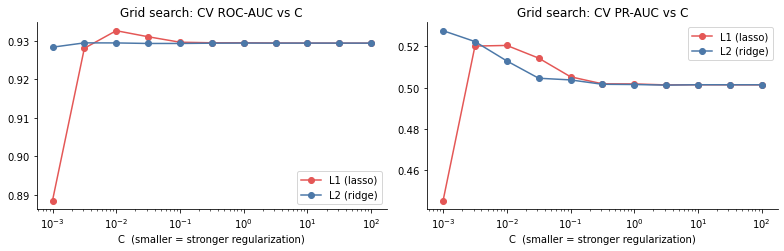

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
for name, color in [("L1 (lasso)", "#E45756"), ("L2 (ridge)", "#4C78A8")]:
    r = fitted[name].cv_results_
    ax[0].semilogx(Cs, r["mean_test_roc_auc"], "o-", color=color, label=name)
    ax[1].semilogx(Cs, r["mean_test_ap"], "o-", color=color, label=name)
ax[0].set_title("Grid search: CV ROC-AUC vs C"); ax[1].set_title("Grid search: CV PR-AUC vs C")
for a in ax: a.set_xlabel("C  (smaller = stronger regularization)"); a.legend()
plt.tight_layout(); plt.show()

---
# 3. Success criteria and results

With ~3-4% positives, accuracy is meaningless (predicting "healthy" for everyone scores ~96%). Criteria on the **held-out 2017-2023 test period**:

| Metric | Why |
|---|---|
| **ROC-AUC** | ranking quality across all thresholds |
| **Precision, recall, F1** | at a fixed threshold: false alarms vs missed distress |
| **Recall in the riskiest 5%** | if an analyst can only review the top 5% of scores, how many distressed firms are caught? |
| **ROC-AUC on currently healthy firms only** | the honest early-warning test: can firms get flagged *before* they are already distressed? |

**Benchmarks:** (1) *persistence*: predict distress next year if distressed now; (2) the **Altman Z-score** (1968) from the same five ratios, with the classic cutoff Z < 1.81.

In [8]:
def topk(y, s, frac=0.05):
    k = max(1, int(len(y) * frac)); idx = np.argsort(-s)[:k]
    return y.values[idx].sum() / max(y.sum(), 1), y.values[idx].mean()

def evaluate(name, s, thr, mask=None):
    p = (s >= thr).astype(int)
    rec5, prec5 = topk(yte, s)
    r = {"Model": name,
         "ROC-AUC": roc_auc_score(yte, s), "PR-AUC": average_precision_score(yte, s),
         "Precision": precision_score(yte, p, zero_division=0), "Recall": recall_score(yte, p),
         "F1": f1_score(yte, p), "Recall @ top 5%": rec5}
    if mask is not None:
        r["ROC-AUC (healthy now)"] = roc_auc_score(yte[mask], s[mask])
    return r

healthy = (test["distress_t"] == 0).values
scores = {name: gs.predict_proba(Xte)[:, 1] for name, gs in fitted.items()}
rows = [evaluate(n, s, 0.5, healthy) for n, s in scores.items()]

# benchmark 1: persistence
pers = test["distress_t"].fillna(0).values.astype(float)
r = evaluate("Persistence (same as last yr)", pers, 0.5); r["ROC-AUC (healthy now)"] = np.nan; rows.append(r)

# benchmark 2: Altman Z (higher Z = safer, so use -Z as the risk score; classic cutoff Z < 1.81)
Z = (1.2*test["wc_ta"] + 1.4*test["re_ta"] + 3.3*test["ebit_ta"] + 0.6*test["mve_tl"] + 1.0*test["sales_ta"])
Z = Z.fillna(Z.median()).values
rz = evaluate("Altman Z-score (1968)", -Z, -1.81, healthy)
rows.append(rz)

results = pd.DataFrame(rows).set_index("Model").round(3)
results

,ROC-AUC,PR-AUC,Precision,Recall,F1,Recall @ top 5%,ROC-AUC (healthy now)
Model,,,,,,,
Baseline (no reg.),0.888,0.431,0.203,0.736,0.318,0.474,0.819
L1 (lasso),0.884,0.442,0.203,0.757,0.320,0.474,0.811
L2 (ridge),0.884,0.450,0.213,0.751,0.332,0.486,0.807
Persistence (same as last yr),0.741,0.312,0.582,0.498,0.537,0.508,NaN
Altman Z-score (1968),0.703,0.151,0.088,0.596,0.153,0.252,0.615


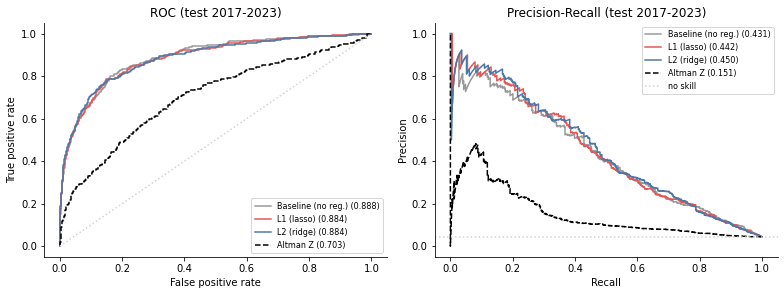

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
cols = {"Baseline (no reg.)": "#999999", "L1 (lasso)": "#E45756", "L2 (ridge)": "#4C78A8"}
for name, s in scores.items():
    fpr, tpr, _ = roc_curve(yte, s); ax[0].plot(fpr, tpr, color=cols[name], label=f"{name} ({roc_auc_score(yte, s):.3f})")
    pr, rc, _ = precision_recall_curve(yte, s); ax[1].plot(rc, pr, color=cols[name], label=f"{name} ({average_precision_score(yte, s):.3f})")
fpr, tpr, _ = roc_curve(yte, -Z); ax[0].plot(fpr, tpr, "k--", label=f"Altman Z ({roc_auc_score(yte, -Z):.3f})")
pr, rc, _ = precision_recall_curve(yte, -Z); ax[1].plot(rc, pr, "k--", label=f"Altman Z ({average_precision_score(yte, -Z):.3f})")
ax[0].plot([0, 1], [0, 1], ":", color="lightgrey"); ax[1].axhline(yte.mean(), ls=":", color="lightgrey", label="no skill")
ax[0].set_title("ROC (test 2017-2023)"); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[1].set_title("Precision-Recall (test 2017-2023)"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Financial ratios / metrics that matter
Coefficients are on standardized features, so they are comparable in size. Positive = higher risk of next-year distress.

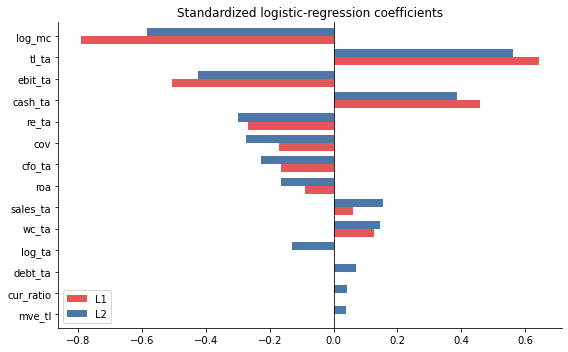

L1 keeps 10 of 14 features (best C = 0.01)


In [10]:
best = fitted["L1 (lasso)"].best_estimator_.named_steps["lr"]
coef = pd.DataFrame({"L1": best.coef_[0],
                     "L2": fitted["L2 (ridge)"].best_estimator_.named_steps["lr"].coef_[0]}, index=feat)
coef = coef.loc[coef["L2"].abs().sort_values().index]
ax = coef.plot.barh(figsize=(8, 5), color=["#E45756", "#4C78A8"], width=0.75)
ax.axvline(0, color="k", lw=0.8); ax.set_title("Standardized logistic-regression coefficients")
plt.tight_layout(); plt.show()
print(f"L1 keeps {(coef['L1'] != 0).sum()} of {len(feat)} features (best C = {fitted['L1 (lasso)'].best_params_['lr__C']:.3g})")

### Does performance hold up over time?
Test-period ROC-AUC for the best model, one feature year at a time (the 2019 feature year is the COVID shock).

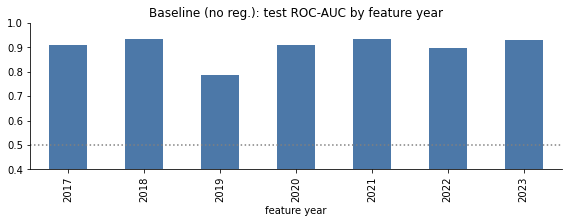

feature year,2017,2018,2019,2020,2021,2022,2023
ROC-AUC,0.911,0.935,0.786,0.908,0.933,0.897,0.93
positives,27.000,35.000,78.000,47.000,50.000,48.000,44.00


In [11]:
best_name = results.loc[[n for n in results.index if n in fitted], "ROC-AUC"].idxmax()
s_best = scores[best_name]
by = []
for y in sorted(test["fy"].unique()):
    k = (test["fy"] == y).values
    if yte[k].sum() >= 5:
        by.append((int(y), roc_auc_score(yte[k], s_best[k]), int(yte[k].sum())))
by = pd.DataFrame(by, columns=["feature year", "ROC-AUC", "positives"]).set_index("feature year")
ax = by["ROC-AUC"].plot.bar(figsize=(8, 3.2), color="#4C78A8"); ax.set_ylim(0.4, 1.0); ax.axhline(0.5, color="grey", ls=":")
ax.set_title(f"{best_name}: test ROC-AUC by feature year"); plt.tight_layout(); plt.show()
by.round(3).T

In [12]:
# auto-generated summary of the results above
b = results.loc[best_name]; pz = results.loc["Persistence (same as last yr)"]; az = results.loc["Altman Z-score (1968)"]
print(f"Best logistic model on the test period: {best_name}")
print(f"  ROC-AUC {b['ROC-AUC']:.3f} | PR-AUC {b['PR-AUC']:.3f} | recall in riskiest 5%: {b['Recall @ top 5%']:.1%}")
print(f"  Among currently healthy firms only: ROC-AUC {b['ROC-AUC (healthy now)']:.3f}")
print(f"  vs Altman Z: ROC-AUC {az['ROC-AUC']:.3f} (healthy-now {az['ROC-AUC (healthy now)']:.3f}) | vs persistence: ROC-AUC {pz['ROC-AUC']:.3f}")
print(f"  Base rate of distress in test period: {yte.mean():.1%} (PR-AUC of a no-skill model)")

Best logistic model on the test period: Baseline (no reg.)
  ROC-AUC 0.888 | PR-AUC 0.431 | recall in riskiest 5%: 47.4%
  Among currently healthy firms only: ROC-AUC 0.819
  vs Altman Z: ROC-AUC 0.703 (healthy-now 0.615) | vs persistence: ROC-AUC 0.741
  Base rate of distress in test period: 4.4% (PR-AUC of a no-skill model)


---
# 4. Key Considerations and Next Steps

**Label and data design**
1. **Is a ratio-based distress label defensible?** It is built from interest coverage, cash flow and leverage, so predicting it from ratios is partly circular. A hard outcome (bankruptcy filing, delisting for cause) would be a cleaner target. I could not find a delisting-*reason* field. Is there a standard source (e.g. a bankruptcy database such as UCLA-LoPucki or Compustat's deletion codes) that should be used?
2. **Exit labeling is an approximation.** A firm that fails shortly after a not-yet-distressed final report (e.g. Lear in 2009) is labeled healthy. 184 retired tickers with a long gap before delisting remain unlabeled.
3. **Universe:** S&P 400/500/600 members are large and rarely fail. The Russell 3000 history was not available through this API; micro-caps would give far more failures.
4. **Point-in-time issues:** sector is today's classification; fundamentals may be restated after first announcement; 34 retired firms (e.g. Lehman) have no data at all.

**Modeling**
1. **Few positives in the test window** (a few hundred over 7 years)
2. **Beyond logistic regression:** random forest / gradient boosting (with class weights or resampling).
3. **Extra features:** macro/credit-cycle variables, industry-relative ratios, year-over-year changes (momentum in ratios), sector dummies.

**Next steps:** add tree-based models, year-over-year change features, an out-of-time check on 2024 once more firms report, and consider a rolling-origin evaluation.